# 📈 Lesson 12 · Project 4 · LSTM Maize Price Forecasting

*“Forecasting is easy to do and hard to do honestly. The model is 20 % of the work; the other 80 % is not fooling yourself.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~180 min | 🔴 Advanced | Day 10–11 | Lessons 05–06, 11 (LSTM, windows) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Frame **time-series forecasting** as supervised learning with a **chronological** train/validation/test split
- Spot and avoid the three classic forecasting traps: **look-ahead leakage, scaling leakage, and trend extrapolation**
- Build **honest baselines** (naive, seasonal-naive, ridge regression) and judge every neural model against them
- Train **LSTM/GRU forecasters** with multiple inputs (price, rainfall, fuel, season) and multi-step outputs
- Evaluate with **MAE / RMSE / MAPE / relative-MAE** and analyse error by forecast horizon
- Attach **prediction intervals** and check their *coverage*
- Turn forecasts into a simple **hold-or-sell decision rule** and back-test it, with humility

## 🗺 Roadmap
1. Project brief
2. Explore: trend, seasonality, rainfall lag
3. The traps
4. Chronological split & windows
5. Metrics
6. Baselines
7. LSTM / GRU forecasters
8. Results
9. Forecast plots
10. Prediction intervals
11. Decision rule back-test
12. Report & stretch goals
13. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📋 1. Project brief

> **Client.** A farmers' cooperative stores maize after harvest and must decide **when to sell**. Maize prices swing by 50 % or more within a year. A trustworthy **4-week-ahead price forecast**: with a sense of uncertainty: would improve those decisions.
> **Your job.** Build and *honestly evaluate* an LSTM-based forecaster for the weekly maize price (KES per 90 kg bag) in **Nairobi**, using price history, rainfall, fuel price and the season.

| | |
|:--|:--|
| **Data** | Weekly prices 2011–2025 for **Nairobi, Eldoret, Kisumu** with weekly rainfall and fuel price (🧪 *synthetic*, but modelled on real drivers: inflation trend, two rainy seasons, harvest-cycle seasonality, droughts in 2011/2017/2022, a 2022 fuel shock) |
| **Task** | Given the last **52 weeks**, predict the price **1, 2, 3 and 4 weeks ahead** |
| **Splits (chronological!)** | Train: up to Dec 2020 · Validation: 2021–2022 (includes the 2022 drought) · Test: 2023–2025 |
| **Success criteria** | Beat the **naive** forecast on test MAE at every horizon · compare against **seasonal-naive and ridge** baselines · report *prediction-interval coverage* · state limitations honestly |

> ⚠️ **Honest caveat.** Because the data is simulated, rainfall and fuel *do* drive prices by construction. On real data these relationships are noisier, policy shocks (import duties, export bans) intervene, and your skill advantage would be smaller. The **workflow and the discipline** are what transfer.

---
## 🔭 2. Explore: trend, seasonality and the rain–price lag

783 weeks | train ends at week 521 (2020-12-28) | validation ends at week 625 (2022-12-26) | test ends 2025-12-29


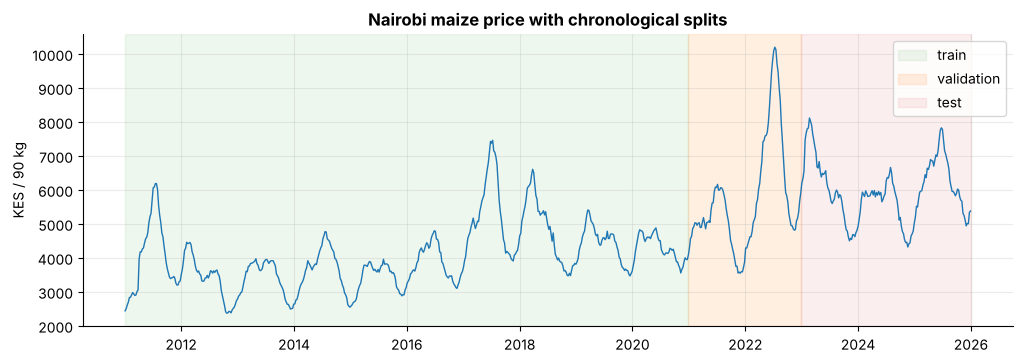

In [2]:
prices_all = dl.load_prices(None)
markets = ["Nairobi", "Eldoret", "Kisumu"]
series = {}
for m in markets:
    df = prices_all[prices_all.market == m].reset_index(drop=True)
    doy = df.date.dt.dayofyear.values
    series[m] = dict(logp=np.log(df.price_kes_90kg.values.astype(float)), price=df.price_kes_90kg.values.astype(float),
                     rain=df.rainfall_mm.values, fuel=df.fuel_kes_per_litre.values,
                     sin=np.sin(2 * np.pi * doy / 365.25), cos=np.cos(2 * np.pi * doy / 365.25))
dates = pd.to_datetime(prices_all[prices_all.market == "Nairobi"].date.values)
n = len(dates)
t_tr = int(np.where(dates <= "2020-12-31")[0].max()); t_va = int(np.where(dates <= "2022-12-31")[0].max())
print(f"{n} weeks | train ends at week {t_tr} ({dates[t_tr].date()}) | validation ends at week {t_va} ({dates[t_va].date()}) | test ends {dates[-1].date()}")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(dates, series["Nairobi"]["price"], lw=1)
ax.axvspan(dates[0], dates[t_tr], color="tab:green", alpha=.08, label="train"); ax.axvspan(dates[t_tr], dates[t_va], color="tab:orange", alpha=.12, label="validation")
ax.axvspan(dates[t_va], dates[-1], color="tab:red", alpha=.08, label="test"); ax.legend(); ax.set(ylabel="KES / 90 kg", title="Nairobi maize price with chronological splits")
plt.show()

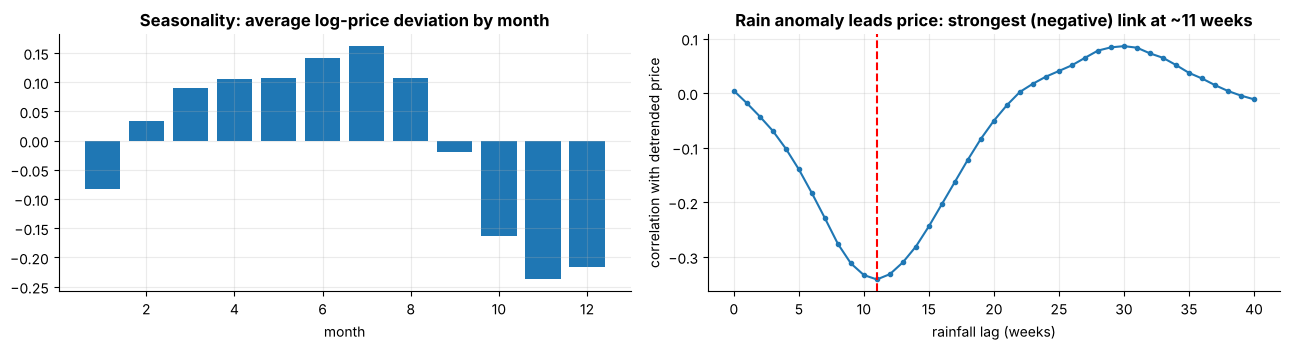

In [3]:
s = pd.Series(series["Nairobi"]["logp"])
detrended = s - s.rolling(53, center=True).mean()                 # remove the slow trend, keep the seasonal/short-term swings
month = dates.month
seasonal = detrended.groupby(month).mean()

rain_s = pd.Series(series["Nairobi"]["rain"]).rolling(4).mean()
week = np.minimum(dates.isocalendar().week.values, 52)
rain_anom = rain_s - rain_s.groupby(week).transform("mean")        # rainfall relative to what's normal for that week
lags = np.arange(0, 41)
xcorr = [detrended.corr(rain_anom.shift(k)) for k in lags]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(seasonal.index, seasonal.values); ax[0].set(title="Seasonality: average log-price deviation by month", xlabel="month")
ax[1].plot(lags, xcorr, "o-", ms=3); best = lags[int(np.nanargmin(xcorr))]
ax[1].axvline(best, c="r", ls="--"); ax[1].set(title=f"Rain anomaly leads price: strongest (negative) link at ~{best} weeks", xlabel="rainfall lag (weeks)", ylabel="correlation with detrended price")
plt.tight_layout(); plt.show()

Three things to notice, each of which will shape the model:

1. **Trend**: prices rise ~4.5 %/yr. A network trained on 2011–2020 levels would see *unprecedented* values in 2025 → we'll model **relative changes**, not absolute levels.
2. **Seasonality**: prices dip after the harvest and peak in the lean months → give the model the **time of year** (as `sin`/`cos` so December and January are neighbours).
3. **Rainfall leads price by ~3 months** (less rain → higher prices later). An LSTM with a 52-week window *can* see this; a model that only sees prices cannot.

---
## 🪤 3. The three traps of forecasting

| Trap | What goes wrong | Our defence |
|:--|:--|:--|
| **1. Random splits / look-ahead** | Shuffling windows puts 2024 data in training and tests on 2023: the model "knows the future" | **Chronological split**; test is strictly later than train |
| **2. Scaling leakage** | Normalising with statistics of the *whole* series leaks future levels into training | Fit any scaler on **train only** |
| **3. Trend extrapolation** | Networks can't predict values far outside the range they trained on | Use **relative features** (price relative to the last week in the window) and predict **log-changes** |

> 🧠 **Rule of thumb:** *at every moment in your pipeline, ask "would this number have been known at forecast time?"* If not, it's leakage.

---
## 🪟 4. Chronological split & windows

For an **origin** week $t$ (the last week we've observed), the model sees weeks $t-51\ldots t$ and predicts the **log-change** $\log p_{t+h}-\log p_t$ for $h=1,2,3,4$ (so its output is a *relative* forecast; multiply by today's price to get KES).

**Per-week input features** (all scale-free):
1. `log p − log p_t`: price history *relative to now*
2. `rain / mean_rain`: rainfall (scaled by its *training* mean)
3. `fuel / fuel_t − 1`: fuel price relative to now
4–5. `sin`, `cos` of the day of the year: season

A window belongs to a split if **all of its targets** fall in that split's period (its *inputs* may reach back into earlier periods: that's just history).

In [4]:
W, H = 52, 4
rain_mean = np.mean([series[m]["rain"][:t_tr + 1].mean() for m in markets])      # TRAIN-only statistic

def build(market, split, multi=True):
    """Returns X (N, 52, n_features), Y (N, 4) log-changes, origins (N,): origin = index of the last observed week."""
    d = series[market]
    lo, hi = {"train": (W - 1, t_tr), "val": (t_tr, t_va), "test": (t_va, n - 1)}[split]
    X, Y, origins = [], [], []
    for t in range(lo, hi - H + 1):
        sl = slice(t - W + 1, t + 1)
        feats = [d["logp"][sl] - d["logp"][t]]
        feats += [d["rain"][sl] / rain_mean, d["fuel"][sl] / d["fuel"][t] - 1, d["sin"][sl], d["cos"][sl]] if multi else [d["sin"][sl], d["cos"][sl]]
        X.append(np.stack(feats, -1)); Y.append(d["logp"][t + 1:t + H + 1] - d["logp"][t]); origins.append(t)
    return np.array(X, np.float32), np.array(Y, np.float32), np.array(origins)

def pooled(split, mkts, multi=True):
    parts = [build(m, split, multi) for m in mkts]
    return np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts])

for split in ["train", "val", "test"]:
    X, Y, o = build("Nairobi", split)
    print(f"{split:5s}: X {X.shape}  Y {Y.shape}  origins {dates[o[0]].date()} … {dates[o[-1]].date()}")
X_te, Y_te, origins_te = build("Nairobi", "test")

train: X (467, 52, 5)  Y (467, 4)  origins 2011-12-26 … 2020-11-30
val  : X (101, 52, 5)  Y (101, 4)  origins 2020-12-28 … 2022-11-28
test : X (154, 52, 5)  Y (154, 4)  origins 2022-12-26 … 2025-12-01


---
## 📏 5. Metrics

We convert predicted log-changes back to **KES** (`price_now × exp(change)`) and report:

* **MAE**: average absolute error in KES (easy to explain to a farmer).
* **RMSE**: penalises big misses.
* **MAPE**: average % error (scale-free; careful when values near 0; fine here).
* **Relative MAE** = MAE ÷ MAE of the naive forecast. **< 1 means we beat "no change"**; this is the number that tells you whether the model adds value.

In [5]:
def to_kes(origins, delta, market="Nairobi"):
    return series[market]["price"][origins][:, None] * np.exp(delta)

def metrics(actual, pred):
    err = pred - actual
    return {"MAE": np.abs(err).mean(0), "RMSE": np.sqrt((err ** 2).mean(0)), "MAPE": (np.abs(err) / actual).mean(0) * 100}

actual_te = to_kes(origins_te, Y_te)
results = {}                                    # model name → predicted log-changes on the test set (N, 4)
def log_result(name, pred_delta):
    results[name] = pred_delta
    m = metrics(actual_te, to_kes(origins_te, pred_delta))
    print(f"{name:34s} MAE by horizon (KES): {np.round(m['MAE']).astype(int)}   MAPE@4w {m['MAPE'][-1]:.1f}%")

---
## 🧱 6. Baselines: the bar to clear

In [6]:
# 1. NAIVE: "next month's price = this week's price"  → predicted log-change = 0
log_result("Naive (no change)", np.zeros_like(Y_te))

# 2. SEASONAL NAIVE: "prices will move as they did over the same weeks LAST year"
lp = series["Nairobi"]["logp"]
log_result("Seasonal naive (last year's move)", np.stack([lp[t + 1 - 52:t + H + 1 - 52] - lp[t - 52] for t in origins_te]))

# 3. RIDGE REGRESSION on the flattened window: a classical, fast, linear model
from sklearn.linear_model import Ridge
Xa, Ya = pooled("train", ["Nairobi"])
ridge = Ridge(alpha=1.0).fit(Xa.reshape(len(Xa), -1), Ya)
log_result("Ridge (Nairobi only)", ridge.predict(X_te.reshape(len(X_te), -1)))
Xp, Yp = pooled("train", markets)
ridge_p = Ridge(alpha=1.0).fit(Xp.reshape(len(Xp), -1), Yp)
log_result("Ridge (3 markets pooled)", ridge_p.predict(X_te.reshape(len(X_te), -1)))

Naive (no change)                  MAE by horizon (KES): [145 243 344 427]   MAPE@4w 7.2%
Seasonal naive (last year's move)  MAE by horizon (KES): [198 336 465 590]   MAPE@4w 9.5%


Ridge (Nairobi only)               MAE by horizon (KES): [116 178 226 264]   MAPE@4w 4.4%
Ridge (3 markets pooled)           MAE by horizon (KES): [116 173 222 262]   MAPE@4w 4.3%


> ⚠️ **Watch out**: Don't skip this step! A shocking number of published 'deep learning forecasts' fail to beat the naive baseline once evaluated honestly. If your LSTM can't beat ridge regression, **say so**: that is a valid scientific result, and often the right engineering call (simpler is cheaper and more explainable).

---
## 🧠 7. LSTM / GRU forecasters

**Model.** `LSTM(n_features → 32 hidden)` reads the 52-week window; the **last hidden state** goes through dropout and a `Linear(32 → 4)` that outputs the four standardised log-changes (many-to-one, multi-output). Training details that matter for small data:

* **Huber loss**: robust to drought-spike outliers (Lesson 03).
* **Early stopping** on validation loss, restoring the best weights (Lesson 14 explains it fully).
* **Gradient clipping**, **weight decay**, **dropout**: three cheap regularisers for a model trained on only a few hundred windows.
* **More data via pooling:** Eldoret and Kisumu share weather and macro conditions with Nairobi. Training on *all three markets' training periods* triples the examples (testing stays on Nairobi's test period).
* **Ensembling:** average the predictions of a few seeds: a reliable variance-reducer for small-data networks.

In [7]:
class Forecaster(nn.Module):
    def __init__(self, kind, n_feat, hidden=32, drop=0.2):
        super().__init__()
        self.rnn = (nn.LSTM if kind == "LSTM" else nn.GRU)(n_feat, hidden, batch_first=True)
        self.drop, self.head = nn.Dropout(drop), nn.Linear(hidden, H)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(self.drop(out[:, -1]))

def train_rnn(kind, train_markets, multi=True, seed=0, epochs=80):
    """Train on pooled markets, early-stop on pooled validation loss. Returns (val_pred, test_pred) log-changes for NAIROBI."""
    dl.set_seed(seed)
    Xtr, Ytr = pooled("train", train_markets, multi); Xva, Yva = pooled("val", train_markets, multi)
    y_sd = Ytr.std(0)                                        # standardise the targets with TRAIN statistics
    model = Forecaster(kind, Xtr.shape[-1])
    T = torch.tensor
    tr = DataLoader(TensorDataset(T(Xtr), T(Ytr / y_sd)), batch_size=32, shuffle=True)
    va = DataLoader(TensorDataset(T(Xva), T(Yva / y_sd)), batch_size=512)
    dl.fit(model, tr, va, nn.HuberLoss(), torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-4), epochs=epochs, device=cpu,
           early_stopper=dl.EarlyStopper(patience=10), grad_clip=1.0, task="regression", verbose=False)
    model.eval()
    Xv_n, _, _ = build("Nairobi", "val", multi); Xt_n, _, _ = build("Nairobi", "test", multi)
    with torch.no_grad():
        return model(T(Xv_n)).numpy() * y_sd, model(T(Xt_n)).numpy() * y_sd

def ensemble(kind, train_markets, multi=True, seeds=(0, 1, 2)):
    runs = [train_rnn(kind, train_markets, multi, s) for s in seeds]
    return np.mean([r[0] for r in runs], 0), np.mean([r[1] for r in runs], 0)

val_preds = {}
for name, kind, mk, multi in [("LSTM · price+season only (Nairobi)", "LSTM", ["Nairobi"], False),
                              ("LSTM · +rain +fuel (Nairobi)", "LSTM", ["Nairobi"], True),
                              ("LSTM · +rain +fuel (3 markets)", "LSTM", markets, True),
                              ("GRU · +rain +fuel (3 markets)", "GRU", markets, True)]:
    val_preds[name], test_pred = ensemble(kind, mk, multi)
    log_result(name, test_pred)

LSTM · price+season only (Nairobi) MAE by horizon (KES): [127 200 284 356]   MAPE@4w 5.8%


LSTM · +rain +fuel (Nairobi)       MAE by horizon (KES): [117 182 241 287]   MAPE@4w 4.7%


LSTM · +rain +fuel (3 markets)     MAE by horizon (KES): [109 165 206 240]   MAPE@4w 4.0%


GRU · +rain +fuel (3 markets)      MAE by horizon (KES): [109 168 215 257]   MAPE@4w 4.2%


---
## 🏆 8. Results

,MAE 1w,MAE 2w,MAE 3w,MAE 4w,RMSE 4w,MAPE 4w %,rel. MAE 4w (vs naive)
model,,,,,,,
Naive (no change),144.53,243.18,344.20,427.12,527.79,7.18,1.00
Seasonal naive (last year's move),198.47,335.95,465.06,589.68,805.33,9.51,1.38
Ridge (Nairobi only),115.62,177.75,226.07,263.54,340.86,4.35,0.62
Ridge (3 markets pooled),115.96,172.54,221.68,262.06,342.42,4.29,0.61
LSTM · price+season only (Nairobi),126.75,200.29,283.61,355.94,456.59,5.77,0.83
LSTM · +rain +fuel (Nairobi),116.61,181.94,241.30,287.11,370.47,4.68,0.67
LSTM · +rain +fuel (3 markets),108.92,165.08,206.12,240.13,303.34,4.00,0.56
GRU · +rain +fuel (3 markets),109.48,168.47,214.87,256.66,322.18,4.25,0.60


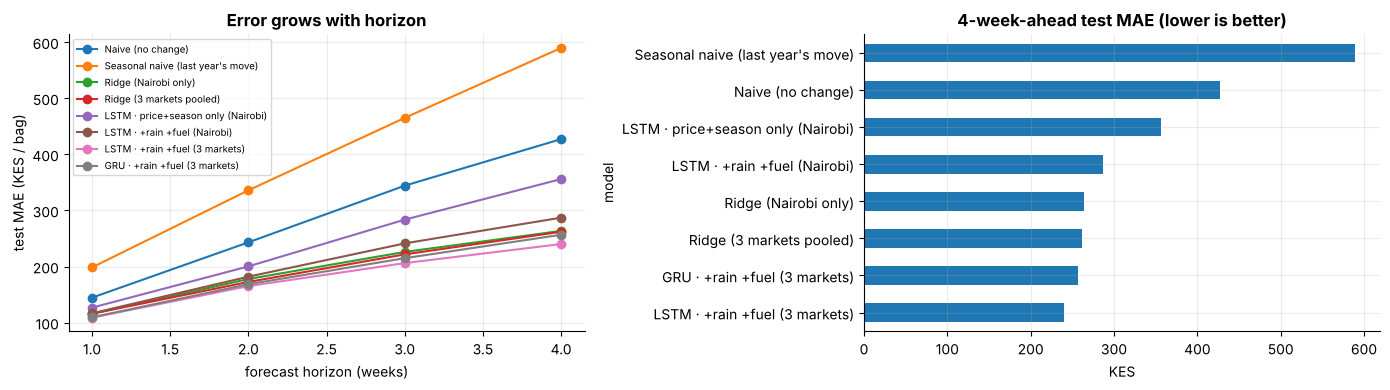

In [8]:
rows = []
for name, pred in results.items():
    m = metrics(actual_te, to_kes(origins_te, pred))
    rows.append({"model": name, **{f"MAE {h}w": m["MAE"][h - 1] for h in range(1, 5)}, "RMSE 4w": m["RMSE"][3], "MAPE 4w %": m["MAPE"][3]})
table = pd.DataFrame(rows).set_index("model")
table["rel. MAE 4w (vs naive)"] = table["MAE 4w"] / table.loc["Naive (no change)", "MAE 4w"]
display(table.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name in results:
    ax[0].plot(range(1, 5), metrics(actual_te, to_kes(origins_te, results[name]))["MAE"], "o-", label=name)
ax[0].set(xlabel="forecast horizon (weeks)", ylabel="test MAE (KES / bag)", title="Error grows with horizon"); ax[0].legend(fontsize=7)
table["MAE 4w"].sort_values().plot.barh(ax=ax[1]); ax[1].set(title="4-week-ahead test MAE (lower is better)", xlabel="KES")
plt.tight_layout(); plt.show()

**How to read the results**

* **Every learned model beats naive**: prices have *predictable structure* (seasonality, lagged rainfall).
* **Seasonal-naive is poor**: copying last year's move imports last year's *noise* (and droughts).
* **Adding rainfall + fuel helps** the LSTM (compare the first two LSTM rows): the lagged-rain effect cannot be learned from prices alone.
* **Ridge is a formidable baseline** on this small dataset. The LSTM's edge comes from **more data (pooling markets)** and **ensembling**. *If a result like this surprises you, good: it is exactly why we always run baselines.*
* Error **grows with horizon**: the further out, the less we know.

> Exact numbers shift with seeds and settings; judge by the *pattern*. And remember the test set has only ~150 overlapping windows: small differences (a few KES) are within noise.

---
## 🔮 9. What do the forecasts look like?

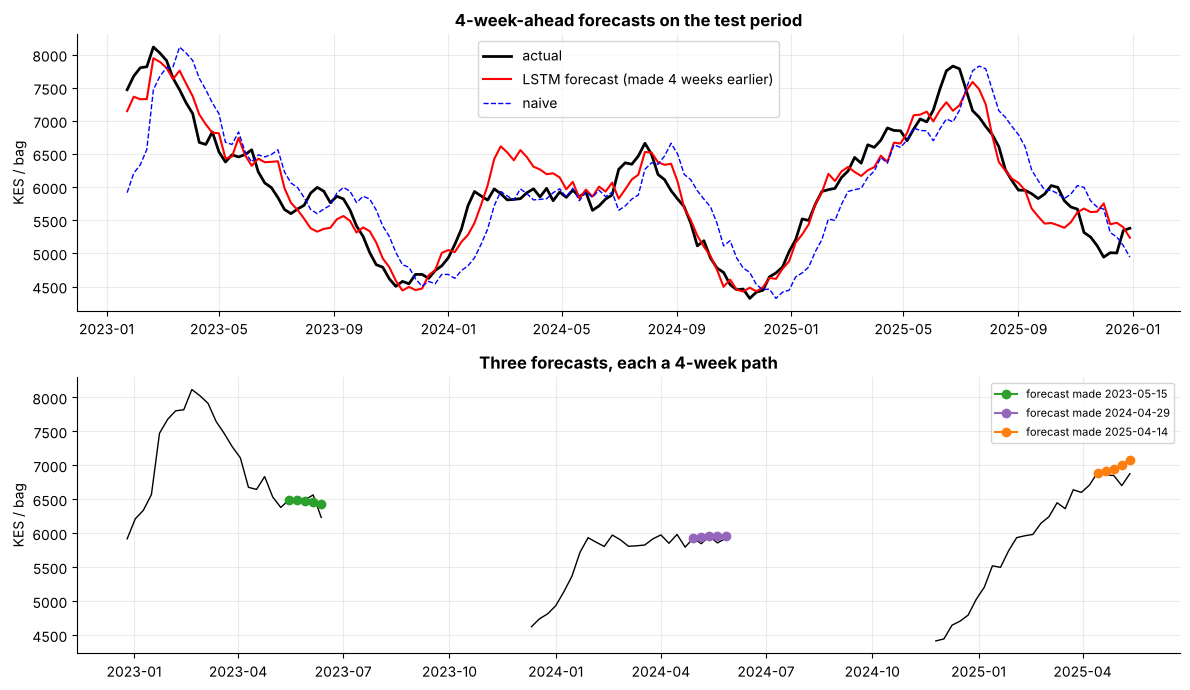

In [9]:
best = "LSTM · +rain +fuel (3 markets)"
pred_kes = to_kes(origins_te, results[best]); naive_kes = to_kes(origins_te, results["Naive (no change)"])
h4 = 3                                                       # index of the 4-week-ahead column
target_dates = dates[origins_te + 4]
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].plot(target_dates, actual_te[:, h4], "k", lw=2, label="actual")
ax[0].plot(target_dates, pred_kes[:, h4], "r", label="LSTM forecast (made 4 weeks earlier)")
ax[0].plot(target_dates, naive_kes[:, h4], "b--", lw=1, label="naive"); ax[0].legend(); ax[0].set(title="4-week-ahead forecasts on the test period", ylabel="KES / bag")
for k, color in zip([20, 70, 120], ["tab:green", "tab:purple", "tab:orange"]):       # three forecast ORIGINS: show the whole 4-step path
    t0 = origins_te[k]; hist = slice(t0 - 20, t0 + 5)
    ax[1].plot(dates[hist], series["Nairobi"]["price"][hist], c="k", lw=1)
    ax[1].plot(dates[t0:t0 + 5], np.r_[series["Nairobi"]["price"][t0], pred_kes[k]], "o-", c=color, label=f"forecast made {dates[t0].date()}")
ax[1].set(title="Three forecasts, each a 4-week path", ylabel="KES / bag"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

---
## 🎚 10. Prediction intervals: how sure are we?

A point forecast hides uncertainty. A simple, honest method: **empirical residual quantiles** (a cousin of *conformal prediction*):

1. On the **validation** set, compute residuals `actual − forecast` (in log-change space) for each horizon.
2. Take their 10th and 90th percentiles → an interval `[forecast + q10, forecast + q90]` that should contain ~80 % of outcomes *if the future behaves like the validation period*.
3. Check the **coverage** on the test set.

80% interval coverage on TEST by horizon: [0.79 0.82 0.79 0.84]  (target 0.80)


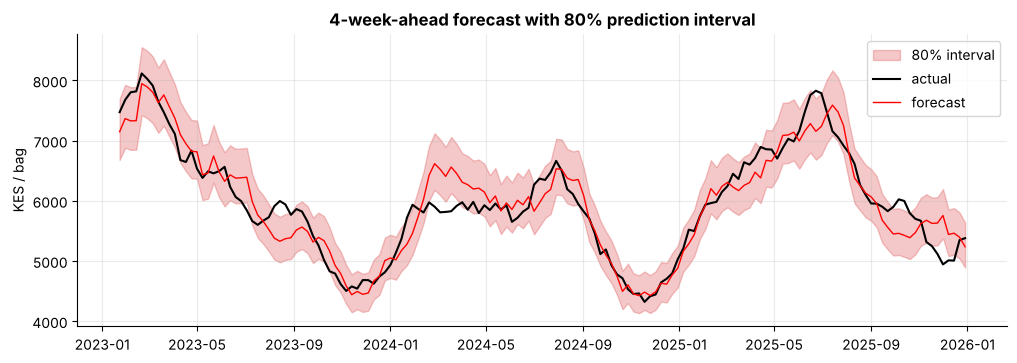

In [10]:
_, Y_va, _ = build("Nairobi", "val")
res_val = Y_va - val_preds[best]                                  # validation residuals (log-change space), shape (N_val, 4)
q_lo, q_hi = np.quantile(res_val, 0.10, axis=0), np.quantile(res_val, 0.90, axis=0)
lo, hi = results[best] + q_lo, results[best] + q_hi
covered = (Y_te >= lo) & (Y_te <= hi)
print("80% interval coverage on TEST by horizon:", covered.mean(0).round(2), " (target 0.80)")

k0 = 3
band_lo, band_hi = to_kes(origins_te, lo)[:, k0], to_kes(origins_te, hi)[:, k0]
plt.figure(figsize=(12, 3.8))
plt.fill_between(target_dates, band_lo, band_hi, alpha=.25, color="tab:red", label="80% interval")
plt.plot(target_dates, actual_te[:, k0], "k", lw=1.5, label="actual"); plt.plot(target_dates, pred_kes[:, k0], "r", lw=1, label="forecast")
plt.legend(); plt.title("4-week-ahead forecast with 80% prediction interval"); plt.ylabel("KES / bag"); plt.show()

> 📝 **Note**: Coverage below the 80 % target means the test period was *more volatile* than validation (or the model is over-confident). Coverage far above means intervals are too wide to be useful. Reporting this is part of an honest forecast. Better methods (quantile loss, conformal prediction, ensembles of different architectures) are stretch goals.

---
## 💼 11. From forecast to decision: a hold-or-sell back-test

Suppose storing a bag for 4 weeks costs **3 %** of its value (losses, financing, space). A simple rule: **hold only if the forecast says the price will rise by more than the storage cost.**

* *Hold gain per bag* = `price(t+4) − price(t) × (1 + 3 %)`; *sell now* gain = 0.
* Compare the rule with **always hold** and **never hold (always sell now)**.

In [11]:
cost = 0.03
p_now = series["Nairobi"]["price"][origins_te]; p_future = actual_te[:, 3]

def backtest(hold_mask):
    gain = np.where(hold_mask, p_future - p_now * (1 + cost), 0.0)
    return gain.mean(), hold_mask.mean()

rows = [("Never hold (sell now)", np.zeros(len(p_now), bool)), ("Always hold", np.ones(len(p_now), bool))]
for name in ["Naive (no change)", "Ridge (3 markets pooled)", best]:
    rows.append((f"Rule using: {name}", (to_kes(origins_te, results[name])[:, 3] / p_now - 1) > cost))
rows.append(("Rule using LSTM, conservative (lower bound)", (to_kes(origins_te, lo)[:, 3] / p_now - 1) > cost))
print(f"{'strategy':48s} {'avg gain / bag (KES)':>22s} {'% of weeks holding':>20s}")
for name, mask in rows:
    g, frac = backtest(mask); print(f"{name:48s} {g:22.1f} {frac:20.0%}")

strategy                                           avg gain / bag (KES)   % of weeks holding
Never hold (sell now)                                               0.0                   0%
Always hold                                                      -207.7                 100%
Rule using: Naive (no change)                                       0.0                   0%
Rule using: Ridge (3 markets pooled)                               92.2                  31%
Rule using: LSTM · +rain +fuel (3 markets)                        101.4                  34%
Rule using LSTM, conservative (lower bound)                        62.0                  12%


> ⚠️ **Watch out**: **Treat this as an illustration, not advice.** ~150 overlapping weekly decisions on *simulated* prices prove nothing about real money. A real study would need real prices, transaction costs, risk preferences, and out-of-sample testing across several seasons. But notice the *method*: translate forecast quality into a business outcome with a transparent rule and compare against trivial strategies.

---
## 📝 12. Report & stretch goals

| Item | Your entry |
|:--|:--|
| Problem, users, decision supported | |
| Data, split dates, **leakage defences** | |
| Features & target definition | relative log-price, rain, relative fuel, sin/cos → 4 log-changes |
| Baselines & their scores | |
| Final model, training recipe, ensembling | |
| Test table (MAE per horizon, rel-MAE, MAPE) | |
| Interval coverage | |
| Decision back-test & caveats | |
| **Limitations** (synthetic data, small test set, regime changes, policy shocks) | |

### 🚀 Stretch goals
1. **Forecast Eldoret or Kisumu**: does the model trained on pooled markets transfer?
2. **Ablate features one at a time** (drop rain, drop fuel, drop season) and measure the cost. Which matters most? Does it match the synthetic data's design?
3. **Longer horizons** (8, 12 weeks): when does the model stop beating naive?
4. **Quantile regression:** train outputs for the 10th/50th/90th percentiles with the pinball loss instead of residual quantiles.
5. **Walk-forward validation:** re-train at several cut-off dates and average the test MAE for a more reliable estimate.
6. **Swap the model:** a small 1-D CNN, or the Transformer encoder from Lesson 13, on the same windows.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 12.1: Chronological split  &nbsp; `⭐`

Write `chronological_masks(dates, train_end, val_end)` returning three boolean arrays `(train, val, test)` over a `DatetimeIndex`: train is `dates <= train_end`, val is `train_end < dates <= val_end`, test is after `val_end`. They must be disjoint and cover everything.

<details><summary>💡 Hint 1</summary>

Compare with `pd.Timestamp(train_end)`.

</details>

<details><summary>💡 Hint 2</summary>

`val = (dates > train_end) & (dates <= val_end)`.

</details>

<details><summary>💡 Hint 3</summary>

Test is simply the complement of the other two: `dates > val_end`.

</details>


In [ ]:
def chronological_masks(dates, train_end, val_end):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
d = pd.date_range("2020-01-01", periods=10, freq="W-MON")
r = chronological_masks(d, "2020-02-01", "2020-02-29")
dl.check("returns three masks", r is not None and len(r) == 3)
dl.check("masks are disjoint and cover all weeks", r is not None and (r[0].astype(int) + r[1] + r[2] == 1).all())
dl.check("order is train → val → test in time", r is not None and r[0].sum() == 4 and r[1].sum() == 4 and r[2].sum() == 2)
dl.check("no test date is earlier than any train date", r is not None and d[r[2]].min() > d[r[0]].max())

---
### 🧩 Problem 12.2: Forecast metrics  &nbsp; `⭐⭐`

Write `forecast_metrics(actual, pred, naive_pred)` returning a dict with `MAE`, `RMSE`, `MAPE` (in %), and `rel_MAE` = MAE of `pred` ÷ MAE of `naive_pred`. All inputs are 1-D arrays.

<details><summary>💡 Hint 1</summary>

`err = pred - actual`.

</details>

<details><summary>💡 Hint 2</summary>

MAPE = `100 * np.mean(np.abs(err) / np.abs(actual))`.

</details>

<details><summary>💡 Hint 3</summary>

`rel_MAE` below 1 means the forecast beats the naive one.

</details>


In [ ]:
def forecast_metrics(actual, pred, naive_pred):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
a = np.array([100., 200., 400.]); p = np.array([110., 190., 380.]); nv = np.array([100., 100., 100.])
m = forecast_metrics(a, p, nv)
dl.check("MAE = 40/3", m is not None and np.isclose(m["MAE"], 40 / 3))
dl.check("RMSE = sqrt(200)", m is not None and np.isclose(m["RMSE"], np.sqrt(200)))
dl.check("MAPE = (10 + 5 + 5)/3 %", m is not None and np.isclose(m["MAPE"], 20 / 3))
dl.check("rel_MAE = (40/3)/(400/3) = 0.1", m is not None and np.isclose(m["rel_MAE"], 0.1))

---
### 🧩 Problem 12.3: Seasonal-naive baseline  &nbsp; `⭐⭐`

Write `seasonal_naive(logp, origins, horizon=4, season=52)`. For each origin `t` it predicts the log-change over the next `horizon` weeks to equal **what happened one season earlier**:
`logp[t+1-season : t+horizon+1-season] − logp[t-season]`. Return an array of shape `(len(origins), horizon)`.

<details><summary>💡 Hint 1</summary>

Loop over origins; slice with `logp[t + 1 - season : t + horizon + 1 - season]`.

</details>

<details><summary>💡 Hint 2</summary>

Subtract `logp[t - season]` (the price one season before the origin).

</details>

<details><summary>💡 Hint 3</summary>

`np.stack` the rows.

</details>


In [ ]:
def seasonal_naive(logp, origins, horizon=4, season=52):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
logp = np.log(100 + np.arange(120) + 5 * np.sin(np.arange(120) * 2 * np.pi / 52))
out = seasonal_naive(logp, np.array([60, 70]), horizon=4, season=52)
dl.check("shape (2, 4)", out is not None and out.shape == (2, 4))
dl.check("first row = last year's change", out is not None and np.allclose(out[0], logp[9:13] - logp[8]))
dl.check("second row", out is not None and np.allclose(out[1], logp[19:23] - logp[18]))

---
### 🧩 Problem 12.4: Prediction-interval coverage  &nbsp; `⭐⭐`

Write `interval_from_residuals(val_residuals, level=0.8)` returning `(q_lo, q_hi)`: the `(1−level)/2` and `(1+level)/2` quantiles of each **column** of the validation residuals:
and `coverage(y, pred, q_lo, q_hi)` returning, per column, the fraction of `y` inside `[pred+q_lo, pred+q_hi]`.

<details><summary>💡 Hint 1</summary>

`np.quantile(res, 0.1, axis=0)` gives one value per column.

</details>

<details><summary>💡 Hint 2</summary>

Inside the interval: `(y >= pred + q_lo) & (y <= pred + q_hi)`; average over axis 0.

</details>


In [ ]:
def interval_from_residuals(val_residuals, level=0.8):
    pass

def coverage(y, pred, q_lo, q_hi):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
rng = np.random.default_rng(0)
res = rng.normal(0, 1, (5000, 2)) * [1, 3]
r = interval_from_residuals(res, 0.8)
dl.check("returns two arrays of length 2", r is not None and len(r) == 2 and len(r[0]) == 2)
dl.check("wider spread → wider interval (col 1 ≈ 3× col 0)", r is not None and np.isclose((r[1] - r[0])[1] / (r[1] - r[0])[0], 3, atol=0.3))
y = rng.normal(0, 1, (5000, 2)) * [1, 3]; pred = np.zeros((5000, 2))
c = coverage(y, pred, *r) if r is not None else None
dl.check("coverage ≈ 0.8 on fresh data from the same distribution", c is not None and np.allclose(c, 0.8, atol=0.03))

---
### 🧩 Problem 12.5: Plug the scaling leak  &nbsp; `⭐`

A colleague standardised the *whole* series before splitting. Write `scale_split(train, test)` that computes mean/std from **`train` only** and returns `(train_scaled, test_scaled)`. For a rising series the scaled test values should lie *outside* the train range: as they honestly would in production.

<details><summary>💡 Hint 1</summary>

`mu, sd = train.mean(), train.std()`

</details>

<details><summary>💡 Hint 2</summary>

Apply the **same** `mu, sd` to both arrays.

</details>


In [ ]:
def scale_split(train, test):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
series_ = np.linspace(100, 200, 100); tr, te = series_[:70], series_[70:]
r = scale_split(tr, te)
dl.check("train is standardised (mean 0, std 1)", r is not None and np.isclose(r[0].mean(), 0, atol=1e-9) and np.isclose(r[0].std(), 1))
dl.check("test uses TRAIN statistics (so it's > train's max)", r is not None and r[1].min() > r[0].max())

---
### 🧩 Problem 12.6: Back-test a hold-or-sell rule  &nbsp; `⭐⭐⭐`

Write `holding_gain(p_now, p_future, hold, cost=0.03)`. `hold` is a boolean array (the rule's decision per week). Return `(avg_gain, fraction_held)` where, for held weeks, gain = `p_future − p_now·(1+cost)`, and for weeks we sell immediately gain = 0.
Then write `decide(p_now, forecast, cost=0.03)` returning the hold mask: hold when `forecast/p_now − 1 > cost`.

<details><summary>💡 Hint 1</summary>

`np.where(hold, p_future - p_now * (1 + cost), 0.0)` builds the per-week gains.

</details>

<details><summary>💡 Hint 2</summary>

Average over **all** weeks (not only the held ones): selling now earns exactly 0.

</details>

<details><summary>💡 Hint 3</summary>

`hold.mean()` is the fraction held.

</details>


In [ ]:
def holding_gain(p_now, p_future, hold, cost=0.03):
    pass

def decide(p_now, forecast, cost=0.03):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
p0 = np.array([100., 100., 100., 100.]); pf = np.array([110., 100., 120., 90.])
h = decide(p0, np.array([106., 101., 130., 95.]))
dl.check("decide → [True, False, True, False]", h is not None and list(h) == [True, False, True, False])
r = holding_gain(p0, pf, h) if h is not None else None
dl.check("avg gain = ((110−103) + (120−103)) / 4 = 6.0", r is not None and np.isclose(r[0], 6.0))
dl.check("fraction held = 0.5", r is not None and np.isclose(r[1], 0.5))

---
## 🏁 Key takeaways
- ✅ Forecasting = supervised learning on **windows**, but the split **must be chronological** and every feature must be knowable at forecast time.
- ✅ Defend against **look-ahead, scaling leakage and trend extrapolation**: use relative features and log-changes, fit scalers on train only.
- ✅ **Always run baselines** (naive, seasonal-naive, ridge). Report **relative MAE**: if you can't beat naive/ridge, say so.
- ✅ LSTM/GRU help most when given **informative inputs** (lagged rainfall, season), **more data** (pooling markets) and **ensembling**: tiny datasets need heavy regularisation.
- ✅ **Error grows with horizon**; report **prediction intervals and their coverage**, not just point forecasts.
- ✅ Connect forecasts to **decisions** with transparent back-tests, and be humble about small, simulated test sets.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why predict the *log-change* relative to the last observed price instead of the price itself?

<details><summary>Answer</summary>

It removes the trend and makes the target scale-free, so the network doesn't have to extrapolate to price levels it never saw in training; log-changes are also roughly symmetric and approximate percentage moves.

</details>

**Q2.** Your LSTM test MAE is 5 % better than naive but 12 % worse than ridge regression. Which would you deploy, and why?

<details><summary>Answer</summary>

Probably ridge: it's simpler, faster, more explainable and more accurate. A fancier model must earn its complexity.

</details>

**Q3.** What's wrong with randomly splitting overlapping windows into train and test?

<details><summary>Answer</summary>

Neighbouring windows share most of their data and overlap in time, so near-copies of test samples sit in training, and the model effectively sees the future: scores are inflated.

</details>

**Q4.** Interval coverage on test is 55 % for a nominal 80 % interval. What might that tell you?

<details><summary>Answer</summary>

The test period was more volatile than validation (regime shift), or the model is over-confident; intervals should be widened/recalibrated, and the forecast treated with more caution.

</details>

---
## 📚 Go deeper (optional)
- Hyndman & Athanasopoulos (*Forecasting: Principles and Practice* (free online, otexts.com/fpp3)) the best forecasting textbook
- Lim & Zohren (2021): *Time-series forecasting with deep learning: a survey*
- Makridakis et al.: the M4/M5 forecasting competitions (when do deep nets beat statistical methods?)
- Angelopoulos & Bates: *A gentle introduction to conformal prediction*
- FAO GIEWS / Kenya's KAMIS: real market price data for East Africa

---
⬅️ Previous: [11 · Recurrent Networks: RNN, LSTM & GRU](11_rnn_lstm_gru.ipynb) &nbsp;|&nbsp; Next: [13 · Transformers & Attention](13_transformers.ipynb) ➡️